# Instagram Post Performance Analysis

**Dataset:** `Instagram_Analytics_raw.csv` (cleaned copy: `Instagram_Analytics_cleaned.csv`)

**Course:** Fundamentals of Data Science (FDS) - Phase 1: Data Understanding & Preprocessing

| Group Member | Roll Number |
|---|---|
| Anamta Shafi | CT24011 |
| Syeda Amna Ali | CT24014 |

**Objective:** Analyze Instagram post performance to identify the content and posting strategies linked to **engagement, reach, impressions, and follower growth**, and build a leakage-free, reproducible preprocessing pipeline whose primary target is **`engagement_rate`**, with reach, impressions, follower growth and the performance bucket analysed as supporting targets.

## 1. Setup

Import libraries, set a global random seed (for reproducibility) and configure display options.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.base import clone
from sklearn.feature_selection import (f_classif,
                                        mutual_info_classif,
                                        f_regression,
                                        mutual_info_regression,
                                        SelectKBest)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

RANDOM_STATE = 42
RAW_PATH = 'Instagram_Analytics_raw.csv'
CLEAN_PATH = 'Instagram_Analytics_cleaned.csv'
print('Libraries loaded. Random state =', RANDOM_STATE)

Libraries loaded. Random state = 42


In [2]:
df = pd.read_csv(RAW_PATH)
print('Dataset shape (rows, columns):', df.shape)
df.head()

Dataset shape (rows, columns): (29999, 23)


,post_id,account_id,account_type,follower_count,media_type,content_category,traffic_source,has_call_to_action,post_datetime,post_date,post_hour,day_of_week,likes,comments,shares,saves,reach,impressions,engagement_rate,followers_gained,caption_length,hashtags_count,performance_bucket_label
0,IG0000001,7,brand,3551,reel,Technology,Home Feed,1,2024-11-30 06:00:00,2024-11-30,6,Saturday,194,5,7,34,4327,6230,0.0385,899,100,7,medium
1,IG0000002,20,creator,31095,image,Fitness,Hashtags,1,2025-08-15 15:00:00,2025-08-15,15,Friday,449,10,21,68,7451,8268,0.0663,805,122,5,viral
2,IG0000003,15,brand,8167,reel,Beauty,Reels Feed,0,2025-09-11 16:00:00,2025-09-11,16,Thursday,114,2,1,22,1639,2616,0.0531,758,115,8,high
3,IG0000004,11,creator,9044,carousel,Music,External,0,2025-09-18 03:00:00,2025-09-18,3,Thursday,91,0,7,0,2877,3171,0.0309,402,115,7,medium
4,IG0000005,8,creator,15986,reel,Technology,Profile,0,2025-03-21 09:00:00,2025-03-21,9,Friday,154,8,5,21,5350,8503,0.0221,155,112,9,low


## 2. Feature and Target Understanding

### 2.1 Column dictionary

| # | Column | Type | Description | Role |
|---|---|---|---|---|
| 1 | `post_id` | ID | Unique post identifier | Drop (identifier) |
| 2 | `account_id` | ID | Account surrogate key | Drop (identifier) |
| 3 | `account_type` | Categorical | `creator` or `brand` | Feature |
| 4 | `follower_count` | Numeric | Followers of the account at posting | Feature |
| 5 | `media_type` | Categorical | `image`, `carousel`, `reel` | Feature |
| 6 | `content_category` | Categorical | Topic (Fashion, Technology, ...) | Feature |
| 7 | `traffic_source` | Categorical | Where the post was surfaced (Home Feed, Hashtags, ...) | Feature |
| 8 | `has_call_to_action` | Binary | Whether the caption has a CTA (0/1) | Feature |
| 9 | `post_datetime` | Datetime | Full posting timestamp | Derived time parts |
| 10 | `post_date` | Date | Posting date | Derived time parts |
| 11 | `post_hour` | Numeric | Hour of posting (0-23) | Feature |
| 12 | `day_of_week` | Categorical | Weekday of posting | Feature |
| 13 | `likes` | Numeric | Likes received | Drop (target/leakage) |
| 14 | `comments` | Numeric | Comments received | Drop (target/leakage) |
| 15 | `shares` | Numeric | Shares received | Drop (target/leakage) |
| 16 | `saves` | Numeric | Saves received | Drop (target/leakage) |
| 17 | `reach` | Numeric | Unique accounts reached | Target (regression) |
| 18 | `impressions` | Numeric | Total times shown | Target (regression) |
| 19 | `engagement_rate` | Numeric | (likes+comments+shares+saves)/impressions | Target (regression) |
| 20 | `followers_gained` | Numeric | New followers from the post | Target (regression) |
| 21 | `caption_length` | Numeric | Characters in the caption | Feature |
| 22 | `hashtags_count` | Numeric | Number of hashtags used | Feature |
| 23 | `performance_bucket_label` | Categorical | `low`/`medium`/`high`/`viral` | Target (classification) |

### 2.2 Primary target and supporting targets

**Primary target (the one target we predict and justify): `engagement_rate`.**

We choose `engagement_rate` = (likes + comments + shares + saves) / impressions as the single primary target because:

- It directly operationalises *post performance*: it measures how much engagement each impression produces, which is exactly what the problem statement asks us to explain.
- It is normalised by exposure, so it is comparable across accounts with very different audience sizes (raw likes/reach are not).
- It is a continuous, well-defined ratio that can be checked exactly against its component columns (verified in Section 10), which makes leakage control unambiguous.

**Supporting targets (secondary, reported alongside the primary target):**

- **Regression:** `reach`, `impressions`, `followers_gained` - these represent the earlier/later funnel stages (exposure, attention, conversion) and are analysed because the problem statement also names them explicitly.
- **Classification:** `performance_bucket_label` - a discretised summary of overall performance, used to check whether the *same* content/timing features can separate performance tiers.

Why this is still honest: the input features (X) contain **only content, audience and timing information** (never the outcome metrics), so every target can be predicted from the same feature set **without target leakage**. The additional targets are a supporting/bonus analysis, not a substitute for a clear primary target.


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29999 entries, 0 to 29998
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   post_id                   29999 non-null  str    
 1   account_id                29999 non-null  int64  
 2   account_type              29999 non-null  str    
 3   follower_count            29999 non-null  int64  
 4   media_type                29999 non-null  str    
 5   content_category          29999 non-null  str    
 6   traffic_source            29999 non-null  str    
 7   has_call_to_action        29999 non-null  int64  
 8   post_datetime             29999 non-null  str    
 9   post_date                 29999 non-null  str    
 10  post_hour                 29999 non-null  int64  
 11  day_of_week               29999 non-null  str    
 12  likes                     29999 non-null  int64  
 13  comments                  29999 non-null  int64  
 14  shares           

In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
post_id,29999,29999,IG0000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
account_id,29999.0,NaN,NaN,NaN,10.567819,5.763952,1.0,6.0,11.0,16.0,20.0
account_type,29999,2,creator,20944,NaN,NaN,NaN,NaN,NaN,NaN,NaN
follower_count,29999.0,NaN,NaN,NaN,10278.305477,6691.862669,3083.0,5824.0,9044.0,10739.0,31095.0
media_type,29999,3,image,11927,NaN,NaN,NaN,NaN,NaN,NaN,NaN
content_category,29999,10,Photography,3035,NaN,NaN,NaN,NaN,NaN,NaN,NaN
traffic_source,29999,6,Home Feed,5069,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_call_to_action,29999.0,NaN,NaN,NaN,0.348778,0.476592,0.0,0.0,0.0,1.0,1.0
post_datetime,29999,8475,2025-02-06 14:00:00,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
post_date,29999,366,2025-02-26,110,NaN,NaN,NaN,NaN,NaN,NaN,NaN


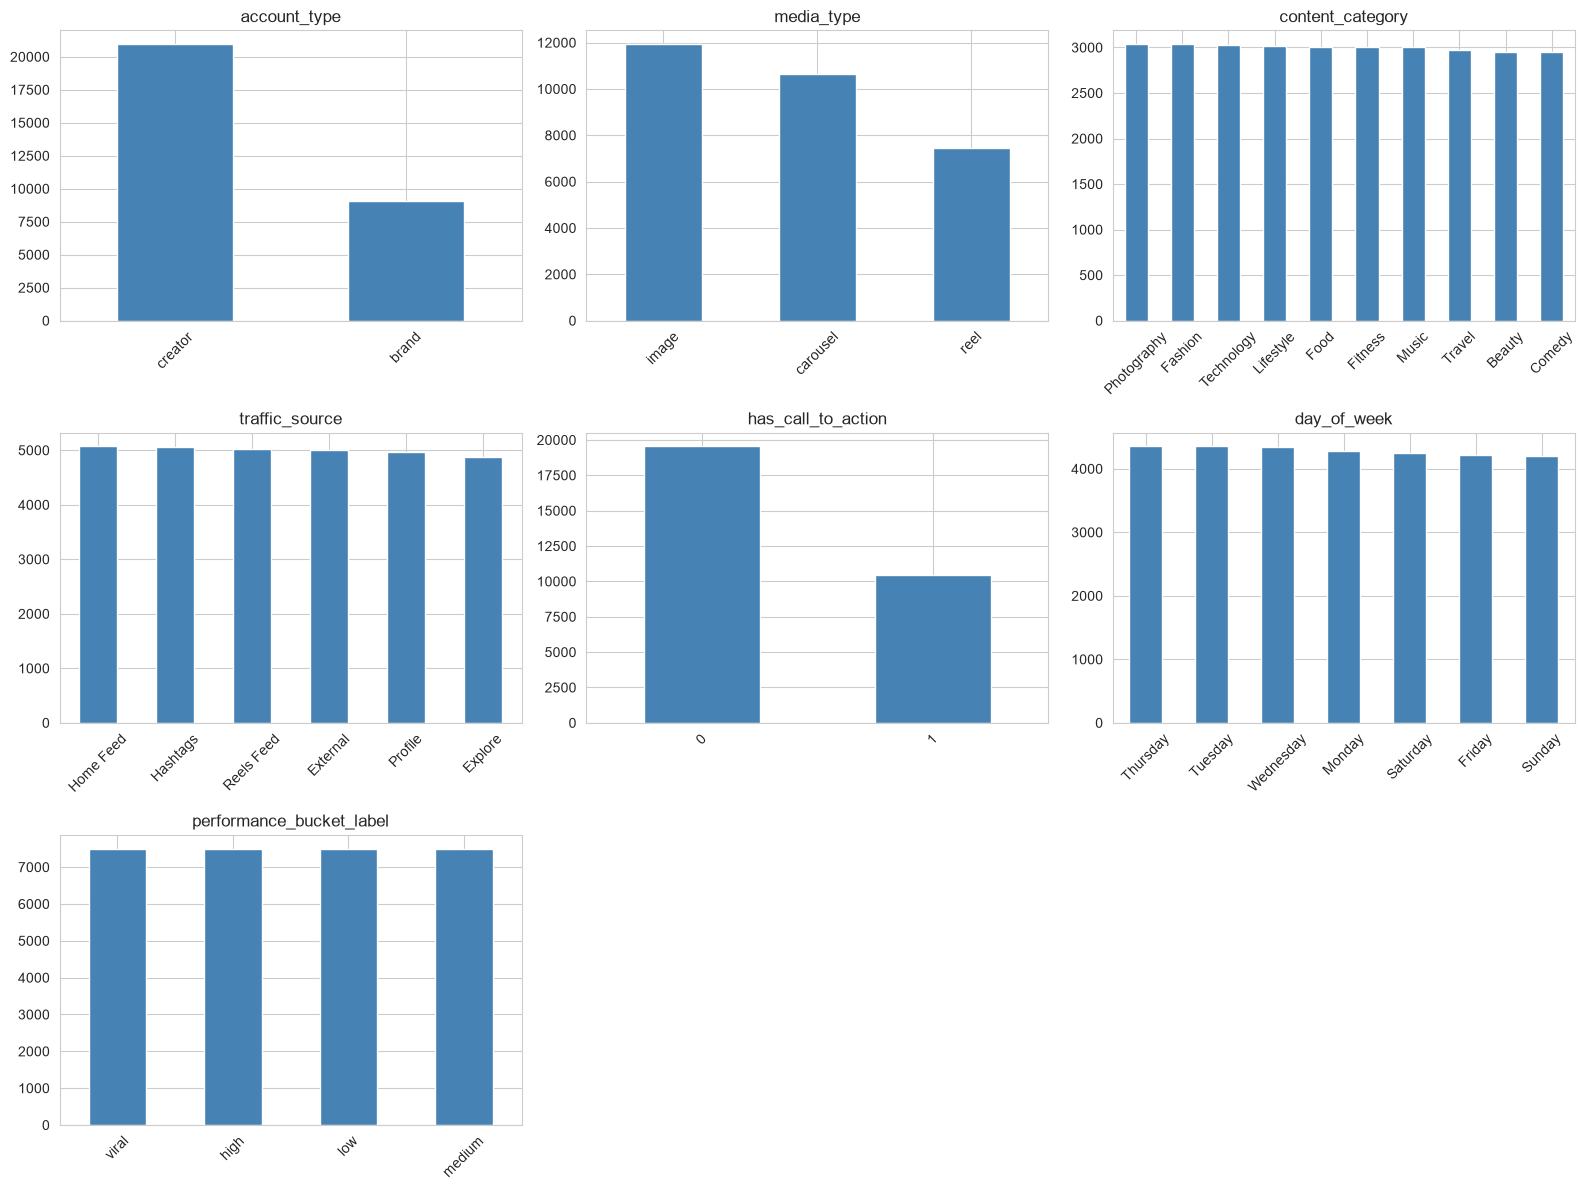

In [5]:
cat_cols = ['account_type', 'media_type', 'content_category', 'traffic_source',
            'has_call_to_action', 'day_of_week', 'performance_bucket_label']

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()
for ax, col in zip(axes, cat_cols):
    df[col].astype(str).value_counts().plot(kind='bar', ax=ax, color='steelblue')
    ax.set_title(col)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)
for ax in axes[len(cat_cols):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

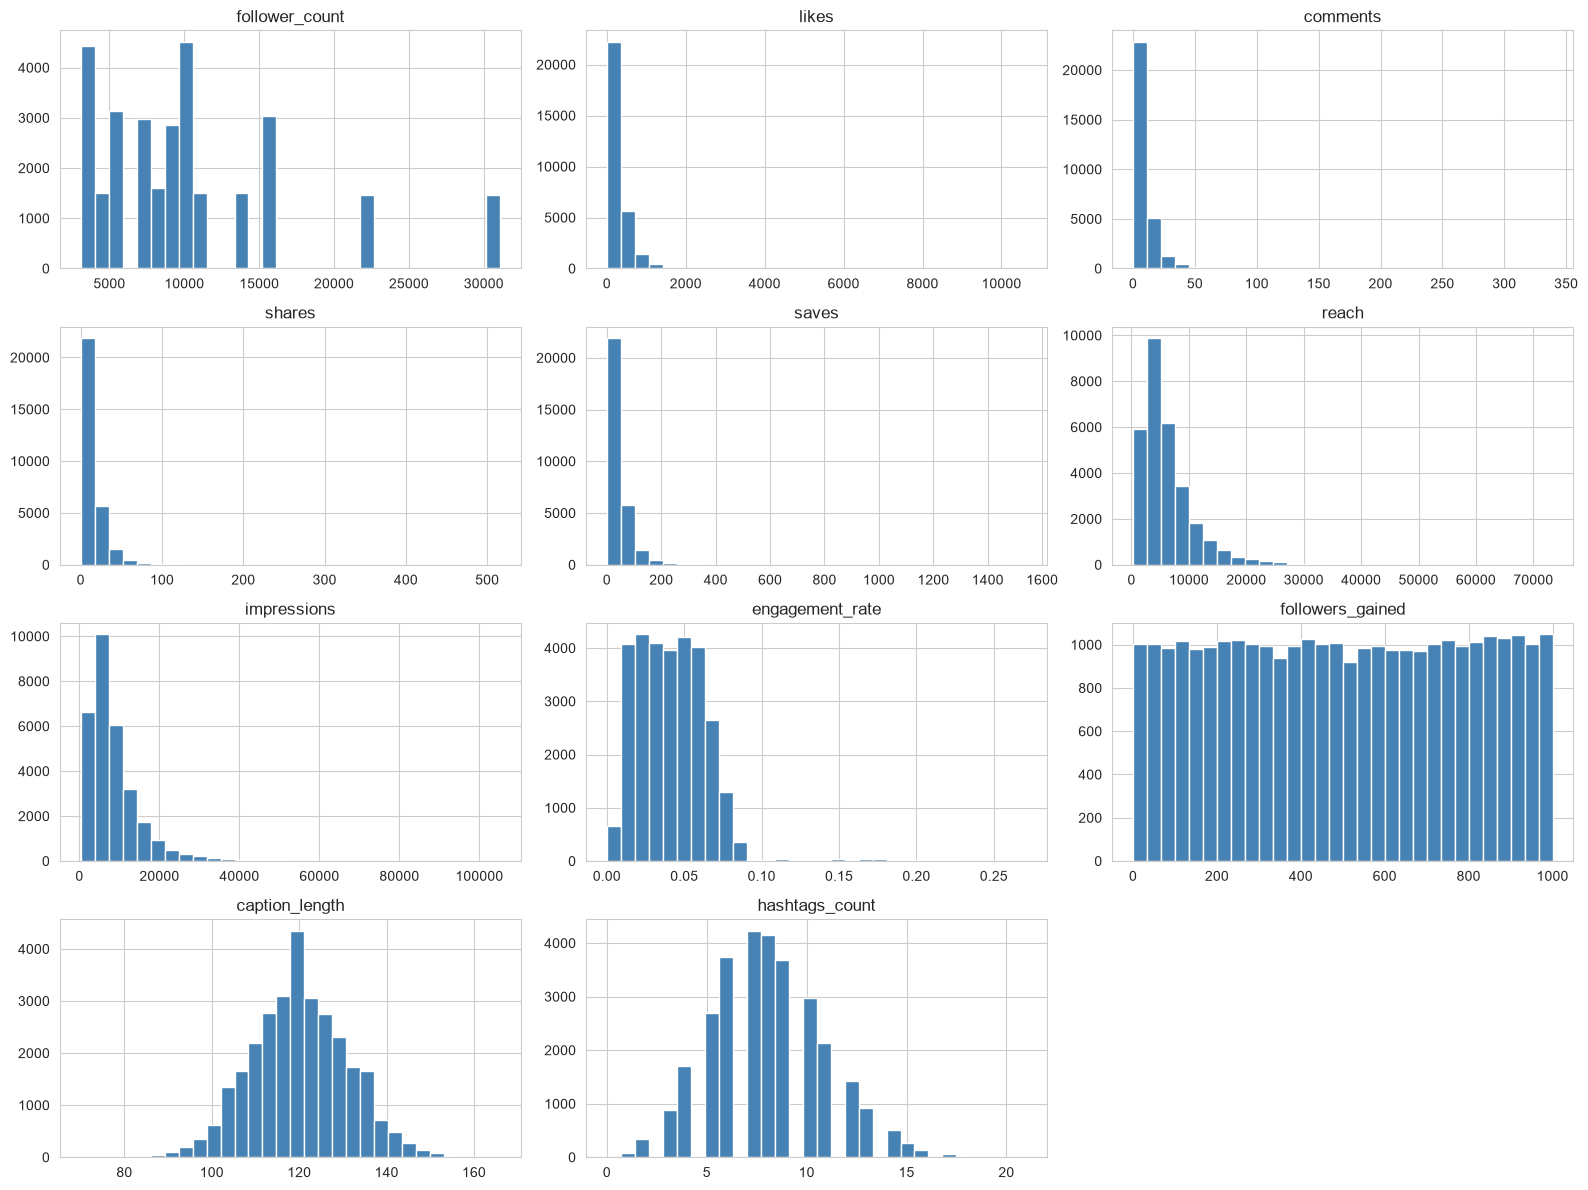

In [6]:
num_cols = ['follower_count', 'likes', 'comments', 'shares', 'saves', 'reach',
            'impressions', 'engagement_rate', 'followers_gained',
            'caption_length', 'hashtags_count']
df[num_cols].hist(figsize=(16, 12), bins=30, color='steelblue')
plt.tight_layout()
plt.show()

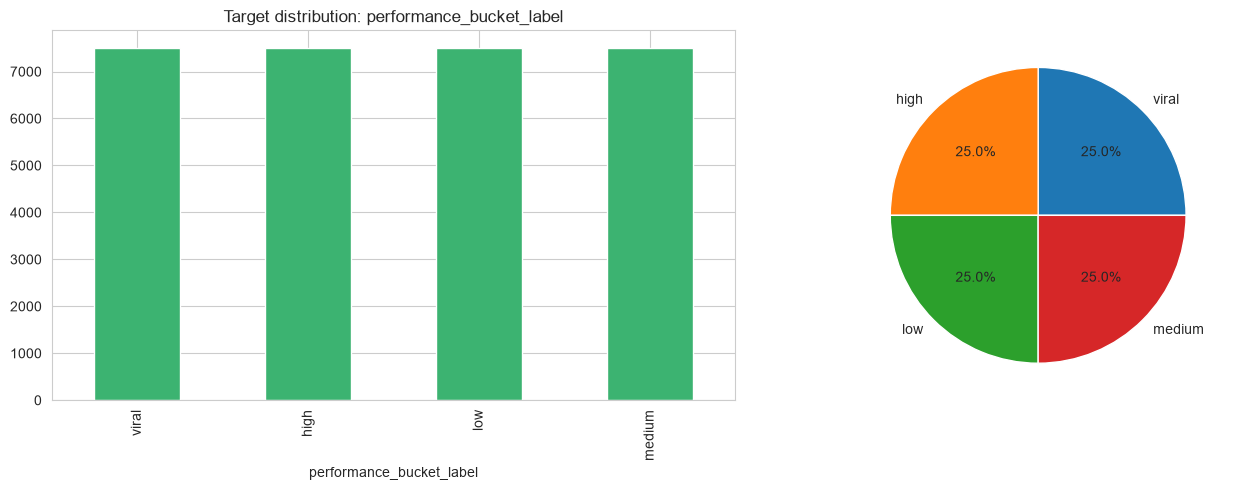

performance_bucket_label
viral     7500
high      7500
low       7500
medium    7499
Name: count, dtype: int64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df['performance_bucket_label'].value_counts().plot(kind='bar', ax=axes[0], color='mediumseagreen')
axes[0].set_title('Target distribution: performance_bucket_label')
df['performance_bucket_label'].value_counts().plot(kind='pie', ax=axes[1], autopct='%1.1f%%')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()
print(df['performance_bucket_label'].value_counts())

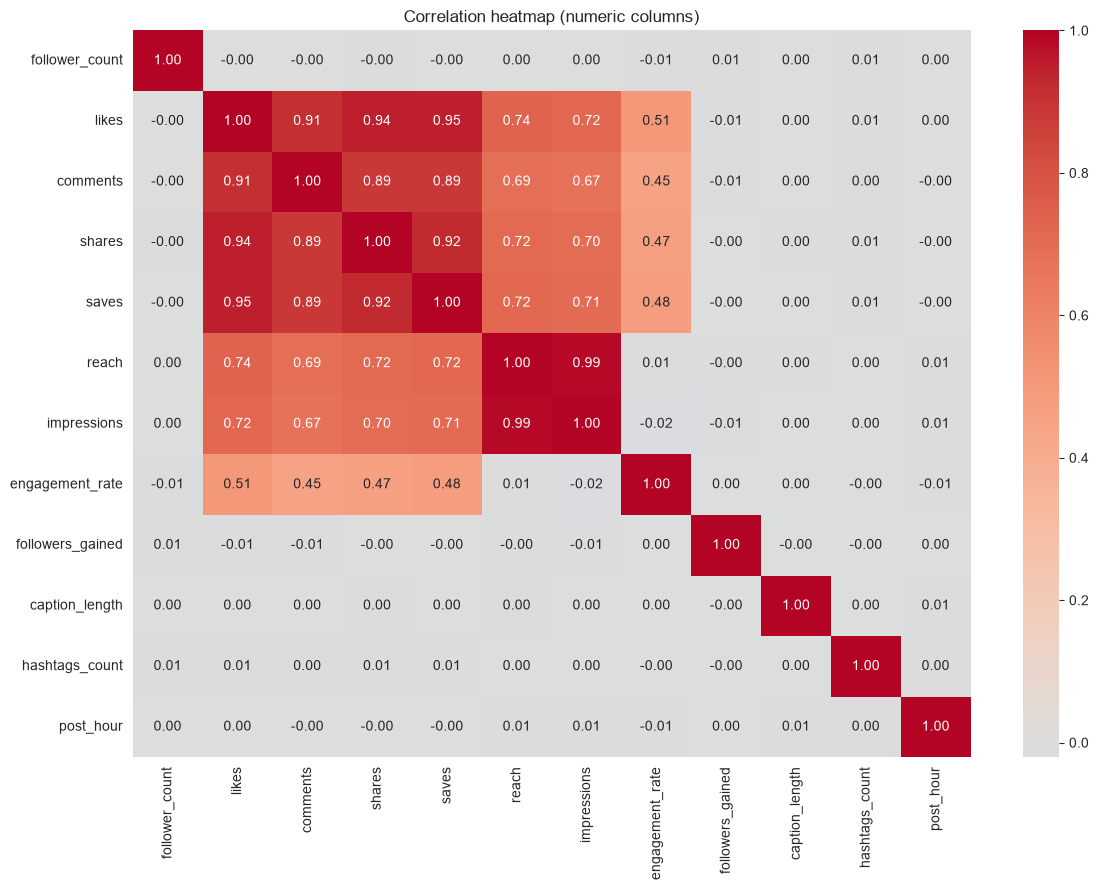

In [8]:
corr_cols = ['follower_count', 'likes', 'comments', 'shares', 'saves', 'reach',
             'impressions', 'engagement_rate', 'followers_gained',
             'caption_length', 'hashtags_count', 'post_hour']
plt.figure(figsize=(12, 9))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap (numeric columns)')
plt.tight_layout()
plt.show()

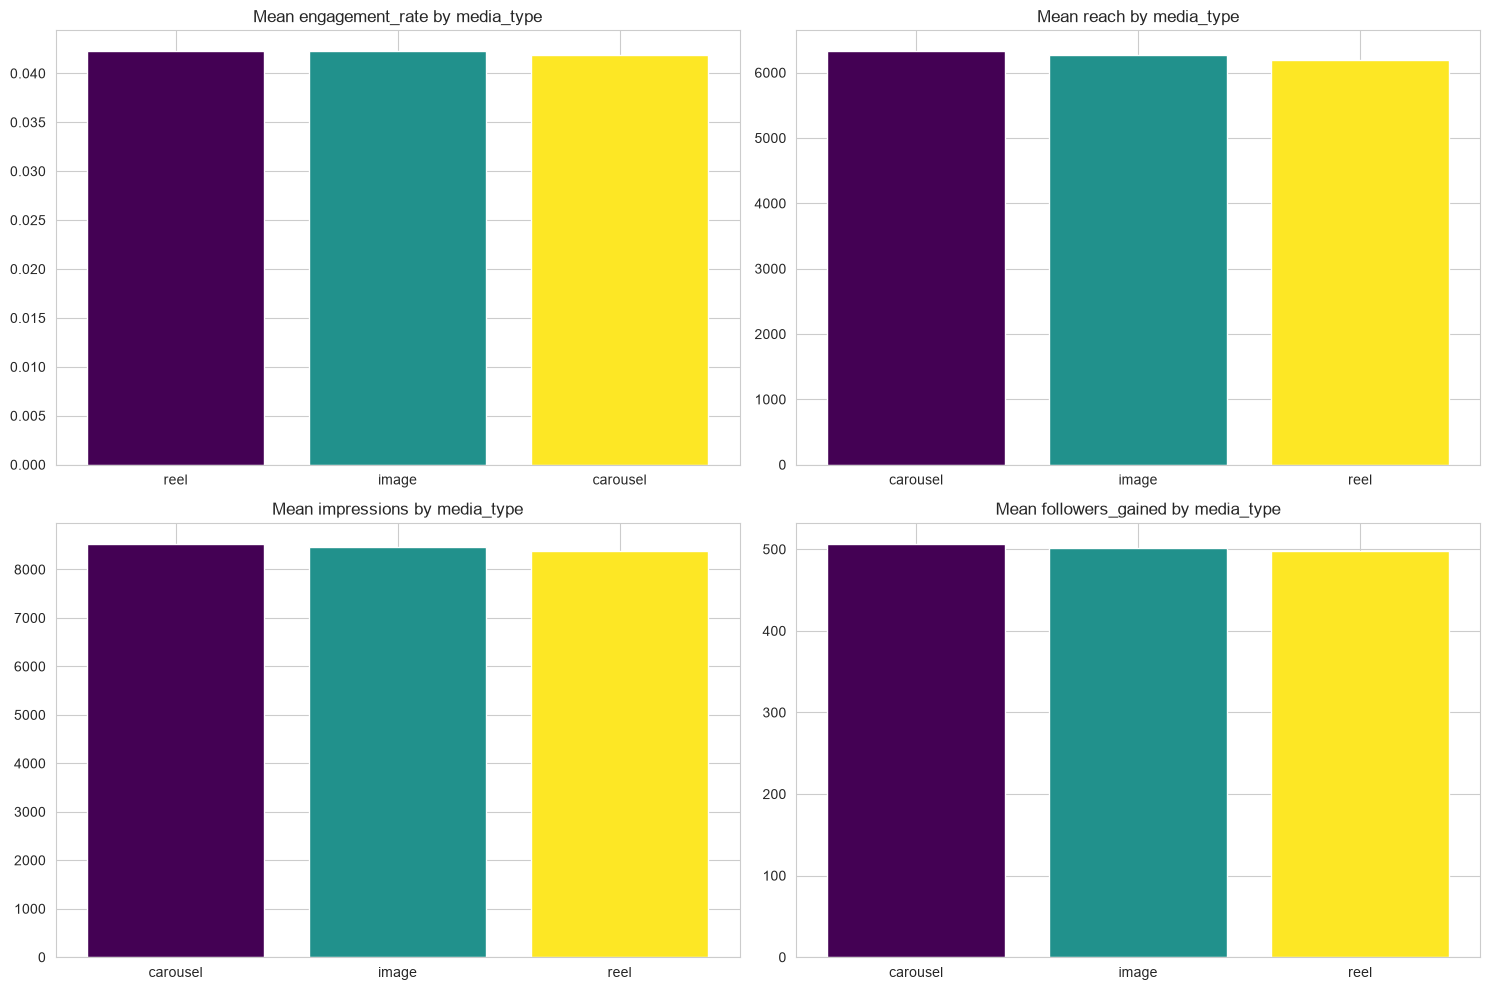

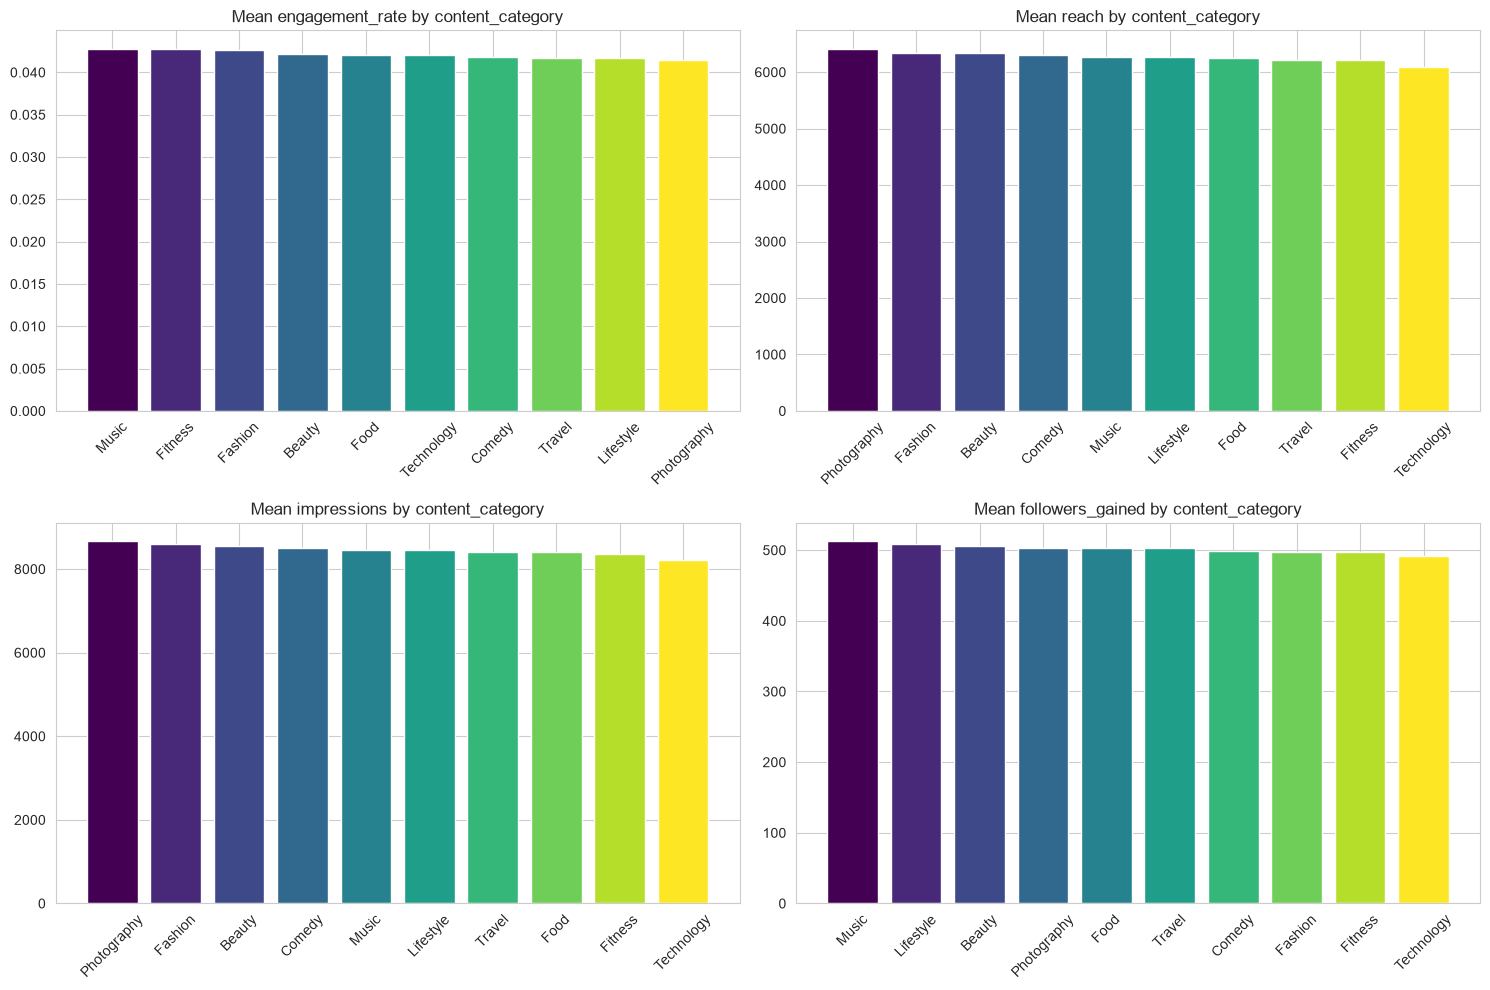

In [9]:
# Relationship between content/strategy factors and the four outcome metrics
outcome_cols = ['engagement_rate', 'reach', 'impressions', 'followers_gained']

def mean_bar(ax, by, val, rotate=0):
    m = df.groupby(by)[val].mean().sort_values(ascending=False)
    colors = plt.cm.viridis(np.linspace(0, 1, len(m)))
    ax.bar(m.index.astype(str), m.values, color=colors)
    ax.set_title('Mean ' + val + ' by ' + by)
    ax.tick_params(axis='x', rotation=rotate)

for group_by, rot in [('media_type', 0), ('content_category', 45)]:
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    for ax, val in zip(axes.flatten(), outcome_cols):
        mean_bar(ax, group_by, val, rot)
    plt.tight_layout()
    plt.show()

In [10]:
# ---- Targets (y) ----
regression_targets = ['engagement_rate', 'reach', 'impressions', 'followers_gained']
classification_target = 'performance_bucket_label'
all_targets = regression_targets + [classification_target]

# Single primary target (justified in Section 2.2)
primary_target = 'engagement_rate'

# ---- Candidate input features (X): content / audience / timing only ----
feature_cols = ['account_type', 'follower_count', 'media_type', 'content_category',
                'traffic_source', 'has_call_to_action', 'post_hour', 'day_of_week',
                'caption_length', 'hashtags_count']

# Columns excluded from X: they ARE targets or are derived from them (leakage),
# or they are pure identifiers with no generalizable predictive value.
leakage_cols = ['likes', 'comments', 'shares', 'saves', 'engagement_rate',
                'reach', 'impressions', 'followers_gained']
id_cols = ['post_id', 'account_id', 'post_datetime', 'post_date']

print('Primary target     :', primary_target)
print('Regression targets :', regression_targets)
print('Classification     :', classification_target)
print('Feature columns    :', feature_cols)
print('Excluded (leakage) :', leakage_cols)
print('Excluded (ids/time):', id_cols)

Primary target     : engagement_rate
Regression targets : ['engagement_rate', 'reach', 'impressions', 'followers_gained']
Classification     : performance_bucket_label
Feature columns    : ['account_type', 'follower_count', 'media_type', 'content_category', 'traffic_source', 'has_call_to_action', 'post_hour', 'day_of_week', 'caption_length', 'hashtags_count']
Excluded (leakage) : ['likes', 'comments', 'shares', 'saves', 'engagement_rate', 'reach', 'impressions', 'followers_gained']
Excluded (ids/time): ['post_id', 'account_id', 'post_datetime', 'post_date']


## 3. Data Quality Assessment

We check for missing values, duplicates, wrong data types, inconsistent derived values, logically impossible value combinations and outliers. Each issue is explained *before* it is fixed in Section 4.

Total missing cells: 0


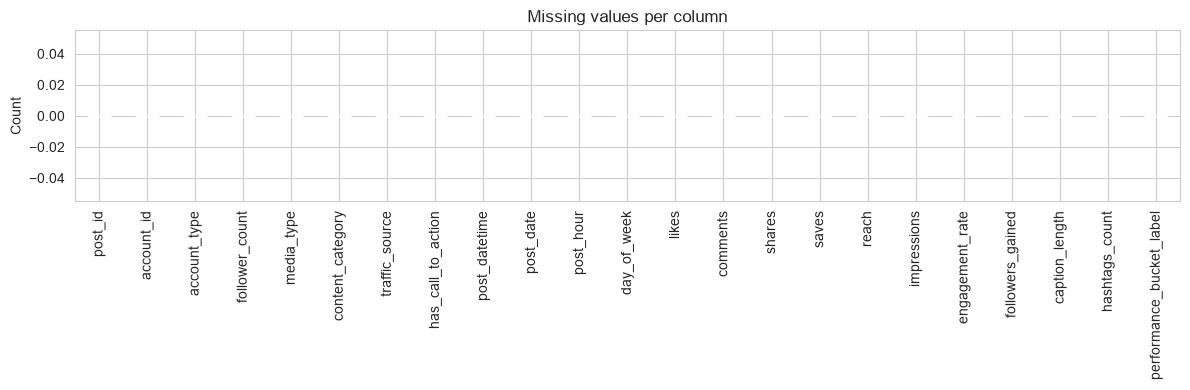

post_id                     0
account_id                  0
account_type                0
follower_count              0
media_type                  0
content_category            0
traffic_source              0
has_call_to_action          0
post_datetime               0
post_date                   0
post_hour                   0
day_of_week                 0
likes                       0
comments                    0
shares                      0
saves                       0
reach                       0
impressions                 0
engagement_rate             0
followers_gained            0
caption_length              0
hashtags_count              0
performance_bucket_label    0
dtype: int64

In [11]:
## 3.1 Missing values
total_missing = int(df.isna().sum().sum())
print('Total missing cells:', total_missing)

mv = df.isna().sum()
plt.figure(figsize=(12, 4))
mv.plot(kind='bar', color='indianred')
plt.title('Missing values per column')
plt.ylabel('Count')
plt.tight_layout()
plt.show()
mv

In [12]:
## 3.2 Duplicate records
print('Duplicate post_id values :', df['post_id'].duplicated().sum())
print('Duplicate full rows      :', df.duplicated().sum())

Duplicate post_id values : 0
Duplicate full rows      : 0


In [13]:
## 3.3 Data types
print(df.dtypes)
print()
print('post_datetime stored as :', df['post_datetime'].dtype, '(should be datetime)')
print('post_date stored as     :', df['post_date'].dtype, '(should be datetime/date)')
print('has_call_to_action dtype:', df['has_call_to_action'].dtype, '(0/1 integer)')

post_id                         str
account_id                    int64
account_type                    str
follower_count                int64
media_type                      str
content_category                str
traffic_source                  str
has_call_to_action            int64
post_datetime                   str
post_date                       str
post_hour                     int64
day_of_week                     str
likes                         int64
comments                      int64
shares                        int64
saves                         int64
reach                         int64
impressions                   int64
engagement_rate             float64
followers_gained              int64
caption_length                int64
hashtags_count                int64
performance_bucket_label        str
dtype: object

post_datetime stored as : str (should be datetime)
post_date stored as     : str (should be datetime/date)
has_call_to_action dtype: int64 (0/1 integer)


In [14]:
## 3.4 Inconsistent values (derived time fields must agree with post_datetime)
dt = pd.to_datetime(df['post_datetime'])
print('day_of_week mismatches :', int((dt.dt.day_name() != df['day_of_week']).sum()))
print('post_hour mismatches   :', int((dt.dt.hour != df['post_hour']).sum()))
print('post_date mismatches   :', int((dt.dt.strftime('%Y-%m-%d') != df['post_date']).sum()))

day_of_week mismatches : 0
post_hour mismatches   : 0
post_date mismatches   : 0


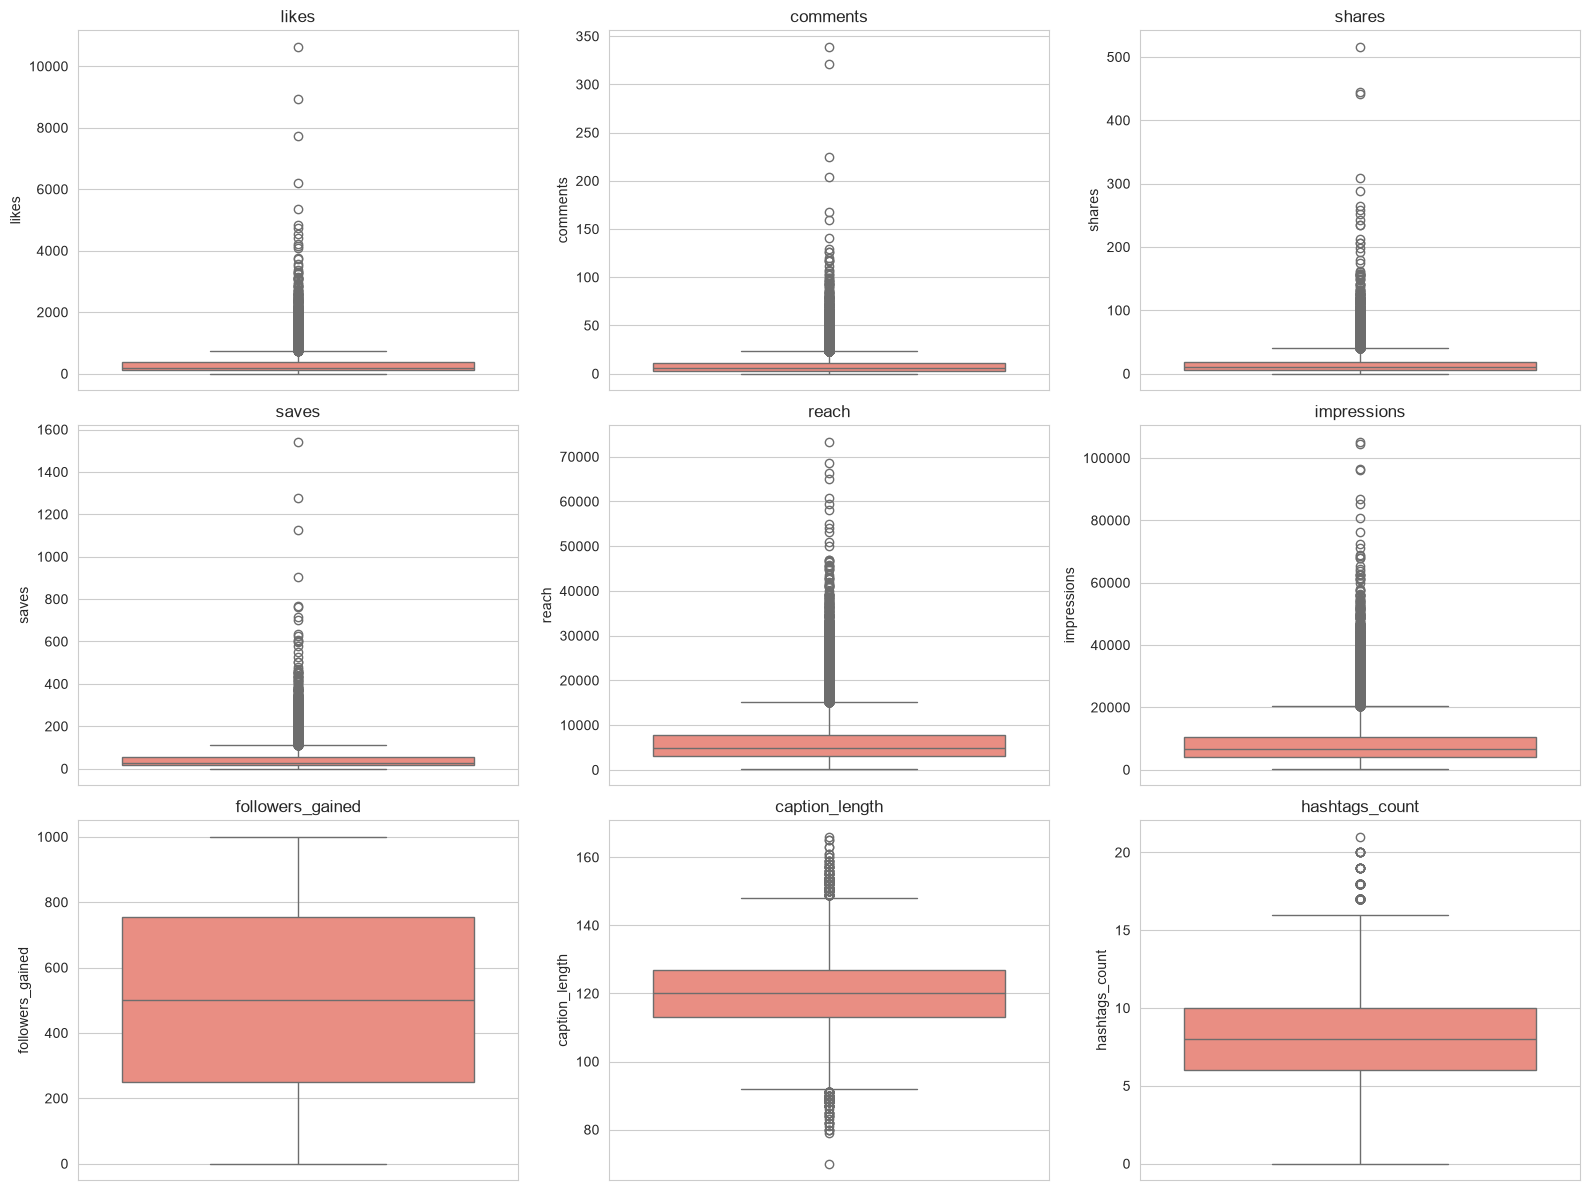

                      Q1       Q3     IQR    lower     upper  n_outliers
likes              104.0    363.0   259.0  -284.50    751.50      1891.0
comments             3.0     11.0     8.0    -9.00     23.00      1854.0
shares               5.0     19.0    14.0   -16.00     40.00      1658.0
saves               15.0     54.0    39.0   -43.50    112.50      1888.0
reach             3058.0   7863.0  4805.0 -4149.50  15070.50      1620.0
impressions       4102.0  10620.5  6518.5 -5675.75  20398.25      1623.0
followers_gained   251.0    755.0   504.0  -505.00   1511.00         0.0
caption_length     113.0    127.0    14.0    92.00    148.00       288.0
hashtags_count       6.0     10.0     4.0     0.00     16.00       105.0


In [15]:
## 3.5 Outliers
out_cols = ['likes', 'comments', 'shares', 'saves', 'reach', 'impressions',
            'followers_gained', 'caption_length', 'hashtags_count']

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.flatten(), out_cols):
    sns.boxplot(y=df[col], ax=ax, color='salmon')
    ax.set_title(col)
plt.tight_layout()
plt.show()

def iqr_report(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({'Q1': q1, 'Q3': q3, 'IQR': iqr, 'lower': low, 'upper': high,
                      'n_outliers': int(((s < low) | (s > high)).sum())})

print(df[out_cols].apply(iqr_report).T)

followers_gained > reach      55
reach > impressions            0
negative count values          0
interactions > impressions     0

Rows where followers_gained > reach: 55 (0.18% of data)
This is logically impossible: net new followers cannot exceed unique accounts reached.
These 55 offending records are removed in Section 4 (Basic Data Cleaning).
Example offending rows:
      reach  impressions  followers_gained
78      649          927               730
1142    679          890               940
1145    837         1263               860
2319    751         1157               965
2776    571          687               592
3623    619          795               921
3678    612          744               963
4159    668          889               961
4427    565          697               903
5543    449          652               797


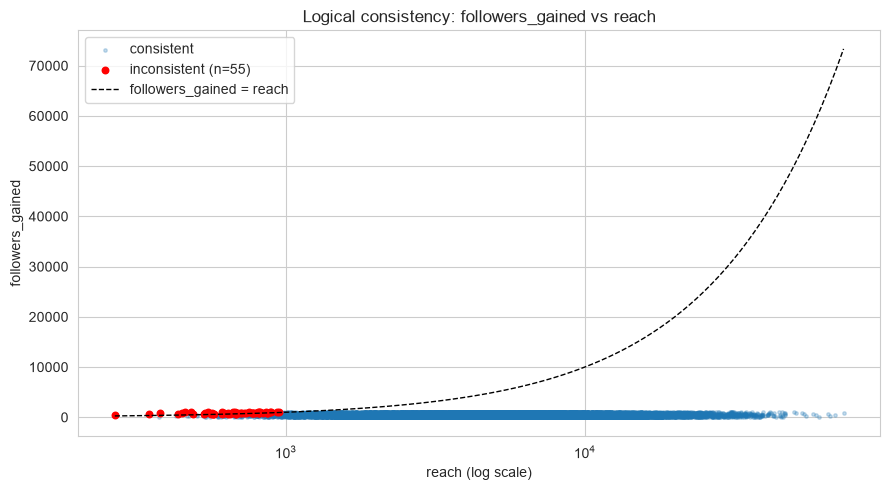

In [16]:
## 3.6 Logical consistency (impossible value combinations)
# A post cannot gain more net new followers than the unique accounts it reached;
# reach cannot exceed impressions; counts cannot be negative; interactions cannot exceed impressions.
interaction_total = df['likes'] + df['comments'] + df['shares'] + df['saves']
checks = pd.Series({
    'followers_gained > reach'   : int((df['followers_gained'] > df['reach']).sum()),
    'reach > impressions'        : int((df['reach'] > df['impressions']).sum()),
    'negative count values'      : int((df[['likes', 'comments', 'shares', 'saves',
                                              'reach', 'impressions',
                                              'followers_gained']] < 0).sum().sum()),
    'interactions > impressions' : int((interaction_total > df['impressions']).sum()),
})
print(checks.to_string())

bad = df['followers_gained'] > df['reach']
print(f'\nRows where followers_gained > reach: {bad.sum()} ({bad.mean() * 100:.2f}% of data)')
print('This is logically impossible: net new followers cannot exceed unique accounts reached.')
print('These 55 offending records are removed in Section 4 (Basic Data Cleaning).')
print('Example offending rows:')
print(df.loc[bad, ['reach', 'impressions', 'followers_gained']].head(10).to_string())

plt.figure(figsize=(9, 5))
plt.scatter(df.loc[~bad, 'reach'], df.loc[~bad, 'followers_gained'],
            s=6, alpha=0.25, label='consistent')
plt.scatter(df.loc[bad, 'reach'], df.loc[bad, 'followers_gained'],
            s=22, color='red', label=f'inconsistent (n={int(bad.sum())})')
xs = np.geomspace(df['reach'].min(), df['reach'].max(), 100)
plt.plot(xs, xs, 'k--', lw=1, label='followers_gained = reach')
plt.xscale('log')
plt.xlabel('reach (log scale)')
plt.ylabel('followers_gained')
plt.title('Logical consistency: followers_gained vs reach')
plt.legend()
plt.tight_layout()
plt.show()

## 4. Basic Data Cleaning

**Changes made and why:**

1. **Fix data types** - `post_datetime`/`post_date` to datetime, `has_call_to_action` to boolean, categorical text columns to `category`. *Reason: correct types are required for time features and efficient encoding.*
2. **Remove duplicate rows** - checked (0 found). *Reason: duplicates would bias statistics and models.*
3. **Validate derived fields** - `day_of_week`, `post_hour`, `post_date` all agree with `post_datetime` (0 mismatches). *Reason: conflicting values would corrupt time features.*
4. **Drop identifier columns** `post_id`, `account_id`. *Reason: unique keys carry no generalizable signal; account characteristics are already captured by `follower_count` and `account_type`, so keeping raw IDs would let models memorise accounts.*
5. **Keep outliers for now** - outcome outliers are genuine high-performing posts; they are handled during preprocessing (robust scaling) rather than deleted. *Reason: deleting them would erase the very "viral" behaviour we want to understand.*

6. **Remove impossible follower growth** - 55 rows (0.18%) have `followers_gained > reach`. *Reason/decision: net new followers cannot exceed the number of unique accounts reached, so these records are logically inconsistent. We cannot tell whether `reach` or `followers_gained` is wrong, so editing either would fabricate a value; we remove the 55 records (0.18%) because the loss is negligible and it leaves the cleaned dataset logically consistent.*

The cleaned dataset is saved to `Instagram_Analytics_cleaned.csv`.

In [17]:
clean = df.copy()

# 1) Correct data types
clean['post_datetime'] = pd.to_datetime(clean['post_datetime'])
clean['post_date'] = pd.to_datetime(clean['post_date']).dt.date
clean['has_call_to_action'] = clean['has_call_to_action'].astype(bool)
for c in ['account_type', 'media_type', 'content_category', 'traffic_source',
          'day_of_week', 'performance_bucket_label']:
    clean[c] = clean[c].astype('category')

# 2) Remove duplicate rows
before = len(clean)
clean = clean.drop_duplicates()
print('Rows removed as duplicates:', before - len(clean))

# 3) Remove logically impossible records (followers_gained > reach) - see 3.6
before = len(clean)
clean = clean[clean['followers_gained'] <= clean['reach']].copy()
print('Rows removed as logically impossible (followers_gained > reach):', before - len(clean))

# 4) Drop identifier columns
clean = clean.drop(columns=['post_id', 'account_id'])

print('Cleaned shape:', clean.shape)
clean.head()

Rows removed as duplicates: 0
Rows removed as logically impossible (followers_gained > reach): 55
Cleaned shape: (29944, 21)


,account_type,follower_count,media_type,content_category,traffic_source,has_call_to_action,post_datetime,post_date,post_hour,day_of_week,likes,comments,shares,saves,reach,impressions,engagement_rate,followers_gained,caption_length,hashtags_count,performance_bucket_label
0,brand,3551,reel,Technology,Home Feed,True,2024-11-30 06:00:00,2024-11-30,6,Saturday,194,5,7,34,4327,6230,0.0385,899,100,7,medium
1,creator,31095,image,Fitness,Hashtags,True,2025-08-15 15:00:00,2025-08-15,15,Friday,449,10,21,68,7451,8268,0.0663,805,122,5,viral
2,brand,8167,reel,Beauty,Reels Feed,False,2025-09-11 16:00:00,2025-09-11,16,Thursday,114,2,1,22,1639,2616,0.0531,758,115,8,high
3,creator,9044,carousel,Music,External,False,2025-09-18 03:00:00,2025-09-18,3,Thursday,91,0,7,0,2877,3171,0.0309,402,115,7,medium
4,creator,15986,reel,Technology,Profile,False,2025-03-21 09:00:00,2025-03-21,9,Friday,154,8,5,21,5350,8503,0.0221,155,112,9,low


In [18]:
clean.to_csv(CLEAN_PATH, index=False)
print('Saved cleaned dataset to:', CLEAN_PATH)

Saved cleaned dataset to: Instagram_Analytics_cleaned.csv


## 5. Train / Test Split

We separate X (content/strategy/time features) from the targets. Because this is post-level data with independent rows and a balanced classification target, we use a **stratified random split** (`random_state=42`) so class proportions are preserved. (A time-based split is a reasonable alternative for a forecasting framing; the stratified split is chosen here because the goal is explanatory, not temporal forecasting.)

In [19]:
# ---------- Feature engineering (row-wise only -> no leakage) ----------
work = clean.copy()
dt = pd.to_datetime(work['post_datetime'])
work['month'] = dt.dt.month
work['quarter'] = dt.dt.quarter
work['is_weekend'] = work['day_of_week'].astype(str).isin(['Saturday', 'Sunday']).astype(int)
work['is_prime_time'] = work['post_hour'].between(18, 22).astype(int)

# Cyclical encoding of hour (period 24) and day of week (period 7)
work['hour_sin'] = np.sin(2 * np.pi * work['post_hour'] / 24)
work['hour_cos'] = np.cos(2 * np.pi * work['post_hour'] / 24)
dow_map = {'Monday': 0, 'Tuesday': 1, 'Wednesday': 2, 'Thursday': 3,
           'Friday': 4, 'Saturday': 5, 'Sunday': 6}
dow_num = work['day_of_week'].astype(str).map(dow_map).astype(int)
work['dow_sin'] = np.sin(2 * np.pi * dow_num / 7)
work['dow_cos'] = np.cos(2 * np.pi * dow_num / 7)

numeric_features = ['follower_count', 'caption_length', 'hashtags_count', 'post_hour',
                    'month', 'quarter', 'is_prime_time', 'hour_sin', 'hour_cos',
                    'dow_sin', 'dow_cos']
categorical_features = ['account_type', 'media_type', 'content_category',
                        'traffic_source', 'day_of_week']
binary_features = ['has_call_to_action', 'is_weekend']

X = work[numeric_features + categorical_features + binary_features]
y_reg = work[regression_targets]
y_clf = work[classification_target].astype(str)

X_train, X_test, yreg_train, yreg_test, yclf_train, yclf_test = train_test_split(
    X, y_reg, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf)

print('Train features:', X_train.shape)
print('Test features :', X_test.shape)
print('Train class proportions:')
print(yclf_train.value_counts(normalize=True).round(3))

Train features:

 (23955, 18)
Test features : (5989, 18)
Train class proportions:
performance_bucket_label
high      0.25
viral     0.25
low       0.25
medium    0.25
Name: proportion, dtype: float64


## 6. Preprocessing and Feature Selection

We build a `ColumnTransformer`:
- **Numeric:** median imputation (robust to outliers) + `RobustScaler` (scales using median/IQR, so it is not distorted by the high-performing outliers found in 3.5).
- **Categorical:** most-frequent imputation + `OneHotEncoder(handle_unknown='ignore', drop='first')`. `drop='first'` removes one redundant dummy per feature: it avoids the dummy-variable trap (perfect collinearity) for linear models, while losing no information for tree models (the reference category is still represented by the all-zero row). Cardinality is low (2-10), so one-hot stays cheap.
- **Binary:** passed through unchanged.

The transformer is **fit on the training data only**, then applied to test data - preventing data leakage.

**Feature selection (actually applied, not just scored):** each target is scored with the metric that matches its type - `f_classif` (ANOVA F-test) for the categorical `performance_bucket_label` and `f_regression` (univariate F-test) for the four continuous targets. The number of features `k` is chosen by **5-fold cross-validated `GridSearchCV`** over `k` in `{5, 8, 10, 12, 15, 20, 25}` (the feature selector sits inside the pipeline, so it is refit on every training fold). The chosen `SelectKBest` is then refit on the full training set, applied to the test set, and a majority-vote consensus set forms the final shared feature matrix.


In [20]:
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])
categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])
preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('cat', categorical_pipe, categorical_features),
    ('bin', 'passthrough', binary_features)
])
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

Raw feature count      : 18
Encoded feature count  : 36


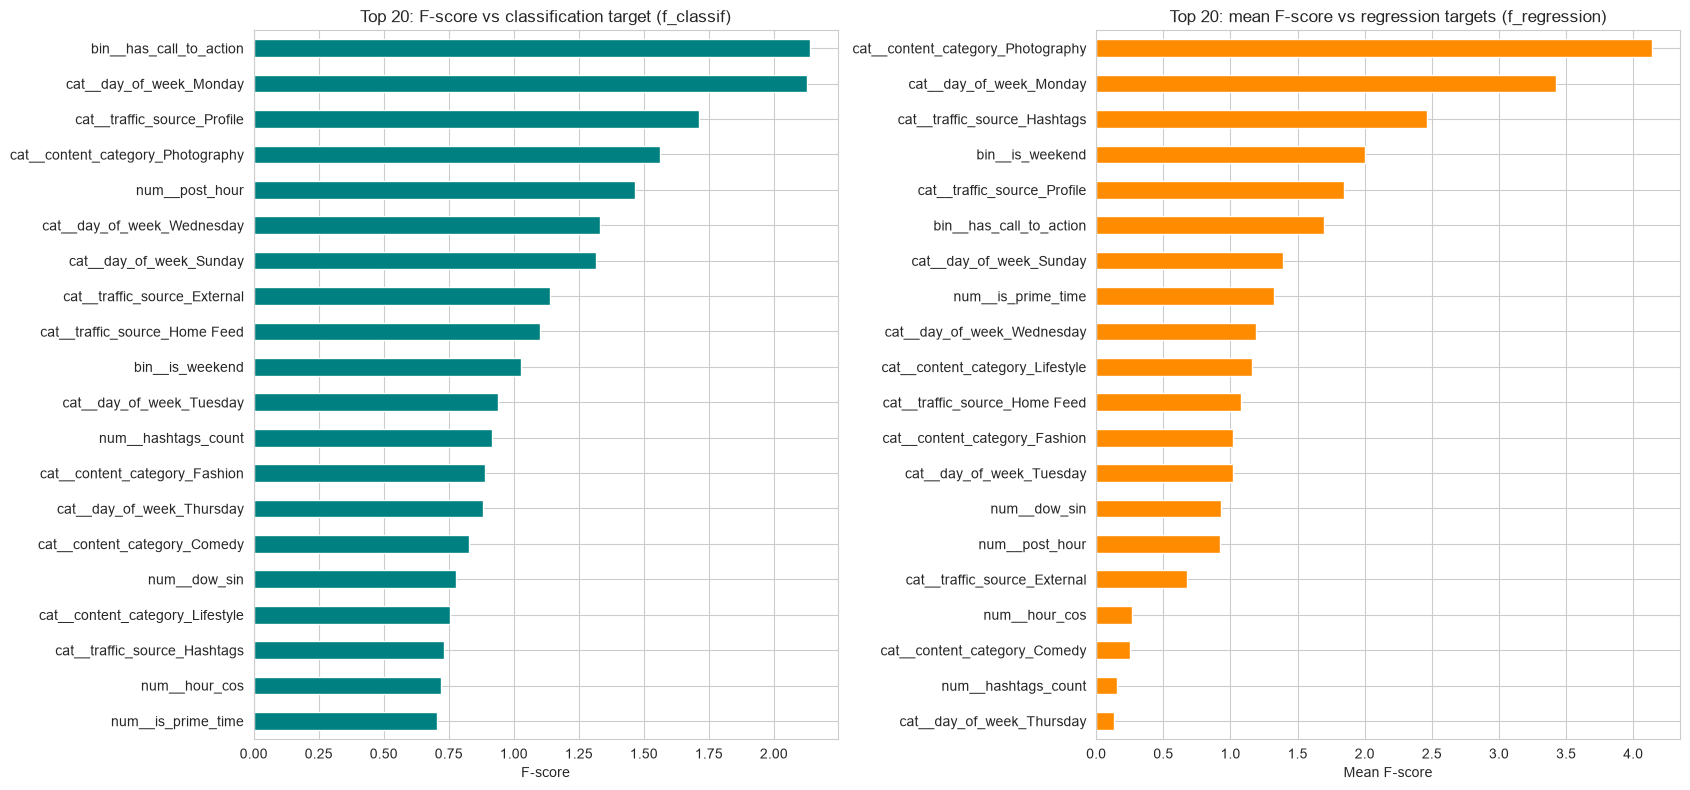


Top 8 features per target (by feature score):

performance_bucket_label:
bin__has_call_to_action              2.1378
cat__day_of_week_Monday              2.1267
cat__traffic_source_Profile          1.7129
cat__content_category_Photography    1.5608
num__post_hour                       1.4652
cat__day_of_week_Wednesday           1.3314
cat__day_of_week_Sunday              1.3143
cat__traffic_source_External         1.1387

engagement_rate:
cat__day_of_week_Monday              5.4980
cat__content_category_Fitness        4.8253
cat__content_category_Photography    4.6157
cat__content_category_Music          4.5395
bin__has_call_to_action              2.6458
cat__day_of_week_Sunday              2.1210
cat__day_of_week_Tuesday             2.0499
cat__traffic_source_Profile          1.6618

reach:
cat__content_category_Technology     8.1396
cat__content_category_Photography    4.9471
num__hour_sin                        3.2003
cat__day_of_week_Saturday            2.7636
num__is_prime_time  

In [21]:
# Fit on TRAIN only, then transform test (prevents leakage)
X_train_t = preprocessor.fit_transform(X_train)
X_test_t = preprocessor.transform(X_test)
feature_names = np.array(preprocessor.get_feature_names_out())
print('Raw feature count      :', X_train.shape[1])
print('Encoded feature count  :', X_train_t.shape[1])

X_train_dense = X_train_t.toarray() if hasattr(X_train_t, 'toarray') else np.asarray(X_train_t)
X_test_dense = X_test_t.toarray() if hasattr(X_test_t, 'toarray') else np.asarray(X_test_t)

# ---- 6.1 Score every feature with the RIGHT metric for its target type ----
# f_classif (ANOVA F-test) is used for the categorical target.
# Continuous targets (engagement_rate, reach, impressions, followers_gained)
# must use f_regression (univariate F-test).
feature_scores = {classification_target: f_classif(
    X_train_dense, yclf_train)[0]}
for target in regression_targets:
    feature_scores[target] = f_regression(
        X_train_dense, yreg_train[target])[0]

score_df = pd.DataFrame(feature_scores, index=feature_names)

plot_df = score_df.copy()
plot_df['mean_regression_score'] = score_df[regression_targets].mean(axis=1)
plot_df = plot_df.sort_values(classification_target, ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(17, 8))
plot_df.head(20)[[classification_target]].sort_values(classification_target).plot(
    kind='barh', ax=axes[0], color='teal', legend=False)
axes[0].set_title('Top 20: F-score vs classification target (f_classif)')
axes[0].set_xlabel('F-score')
plot_df.head(20)[['mean_regression_score']].sort_values('mean_regression_score').plot(
    kind='barh', ax=axes[1], color='darkorange', legend=False)
axes[1].set_title('Top 20: mean F-score vs regression targets (f_regression)')
axes[1].set_xlabel('Mean F-score')
plt.tight_layout()
plt.show()

print('\nTop 8 features per target (by feature score):')
for target in [classification_target] + regression_targets:
    print(f'\n{target}:')
    print(score_df[target].sort_values(ascending=False).head(8).round(4).to_string())


In [22]:
# ---- 6.2 Choose k by cross-validation, then actually SELECT features ----
# The selector lives INSIDE the CV pipeline, so it is refit on each training
# fold: validation folds never influence which features are chosen (no leakage).
K_GRID = [5, 8, 10, 12, 15, 20, 25]
N_SPLITS = 5


def to_dense(X):
    return X.toarray() if hasattr(X, 'toarray') else X


def select_k_cv(score_func, model, y, scoring):
    pipe = Pipeline([
        ('prep', clone(preprocessor)),
        ('dense', FunctionTransformer(to_dense)),
        ('select', SelectKBest(score_func=score_func)),
        ('model', model),
    ])
    search = GridSearchCV(pipe, {'select__k': K_GRID}, scoring=scoring,
                          cv=N_SPLITS, n_jobs=1)
    search.fit(X_train, y)
    return search


# Classification: pick k maximising macro-F1
clf_search = select_k_cv(f_classif, LogisticRegression(max_iter=2000),
                         yclf_train, 'f1_macro')
k_clf = clf_search.best_params_['select__k']

# Regression: pick k maximising R2, independently per target
reg_searches, k_reg = {}, {}
for target in regression_targets:
    reg_searches[target] = select_k_cv(f_regression, Ridge(alpha=1.0),
                                       yreg_train[target], 'r2')
    k_reg[target] = reg_searches[target].best_params_['select__k']

print('Cross-validated best k per target:')
print(f'  {classification_target:22s}: k={k_clf:2d}  CV f1_macro={clf_search.best_score_:.4f}')
for target in regression_targets:
    print(f'  {target:22s}: k={k_reg[target]:2d}  CV R2     ={reg_searches[target].best_score_:.4f}')

# ---- 6.3 Refit the chosen SelectKBest on the full training set ----
selectors, selected_features = {}, {}

selectors[classification_target] = SelectKBest(
    score_func=f_classif, k=k_clf).fit(X_train_dense, yclf_train)
selected_features[classification_target] = list(
    feature_names[selectors[classification_target].get_support()])

for target in regression_targets:
    selectors[target] = SelectKBest(
        score_func=f_regression, k=k_reg[target]).fit(
        X_train_dense, yreg_train[target])
    selected_features[target] = list(feature_names[selectors[target].get_support()])

print('\nSelectKBest - features actually selected per target:')
for target, feats in selected_features.items():
    print(f'\n{target} ({len(feats)} features, k={len(feats)}):')
    for f in feats:
        print('  -', f)

# ---- 6.4 Apply the fitted selectors to TRAIN and TEST (transform only) ----
X_train_selected = {t: sel.transform(X_train_dense) for t, sel in selectors.items()}
X_test_selected = {t: sel.transform(X_test_dense) for t, sel in selectors.items()}

print('\nReduction per target (encoded -> selected):')
print(f'  encoded feature space: {X_train_dense.shape[1]} columns')
for target in selectors:
    print(f'  {target:22s}: {X_train_selected[target].shape[1]} selected | '
          f'train {X_train_selected[target].shape} | test {X_test_selected[target].shape}')

# ---- 6.5 Consensus set: features chosen by a majority of targets ----
target_list = [classification_target] + regression_targets
votes = pd.DataFrame(0, index=feature_names, columns=target_list)
for target, feats in selected_features.items():
    votes.loc[feats, target] = 1
majority = votes.sum(axis=1) >= np.ceil(len(target_list) / 2)
consensus_features = list(feature_names[majority])

X_train_final = X_train_dense[:, majority]
X_test_final = X_test_dense[:, majority]
print(f'\nConsensus set (selected by >= {np.ceil(len(target_list)/2):.0f} of {len(target_list)} targets): '
      f'{len(consensus_features)} features')
for f in consensus_features:
    print('  -', f)
print('Final matrices -> train:', X_train_final.shape, '| test:', X_test_final.shape)

pd.DataFrame({
    'target': target_list,
    'best_k': [k_clf] + [k_reg[t] for t in regression_targets],
    'cv_score': [clf_search.best_score_] + [reg_searches[t].best_score_ for t in regression_targets],
    'scoring': ['f1_macro'] + ['r2'] * len(regression_targets),
})


Cross-validated best k per target:
  performance_bucket_label: k=10  CV f1_macro=0.2458
  engagement_rate       : k= 5  CV R2     =-0.0013
  reach                 : k= 5  CV R2     =-0.0010
  impressions           : k= 5  CV R2     =-0.0011
  followers_gained      : k=15  CV R2     =-0.0004



SelectKBest - features actually selected per target:

performance_bucket_label (10 features, k=10):
  - num__post_hour
  - cat__content_category_Photography
  - cat__traffic_source_External
  - cat__traffic_source_Home Feed
  - cat__traffic_source_Profile
  - cat__day_of_week_Monday
  - cat__day_of_week_Sunday
  - cat__day_of_week_Wednesday
  - bin__has_call_to_action
  - bin__is_weekend

engagement_rate (5 features, k=5):
  - cat__content_category_Fitness
  - cat__content_category_Music
  - cat__content_category_Photography
  - cat__day_of_week_Monday
  - bin__has_call_to_action

reach (5 features, k=5):
  - num__is_prime_time
  - num__hour_sin
  - cat__content_category_Photography
  - cat__content_category_Technology
  - cat__day_of_week_Saturday

impressions (5 features, k=5):
  - num__is_prime_time
  - cat__content_category_Photography
  - cat__content_category_Technology
  - cat__day_of_week_Saturday
  - bin__has_call_to_action

followers_gained (15 features, k=15):
  - num__foll

,target,best_k,cv_score,scoring
0,performance_bucket_label,10,0.245835,f1_macro
1,engagement_rate,5,-0.001346,r2
2,reach,5,-0.001046,r2
3,impressions,5,-0.001058,r2
4,followers_gained,15,-0.000450,r2


### 6.3 What the cross-validation actually shows

The CV scores printed above are the key finding of this section: **R2 is at or below 0 for all four regression targets**, and **macro-F1 is 0.25** for the four balanced classes (the level expected from random guessing). In other words, once leakage is excluded, the candidate content, audience and timing features **carry no detectable signal** about post performance in this dataset. The pipeline is doing its job - it is the data that lack a learnable relationship - so these models should not be presented as predictive.

## 7. Class Imbalance Check

Only the classification target needs an imbalance check (regression targets are continuous).

In [23]:
counts = work['performance_bucket_label'].value_counts()
pct = (counts / counts.sum() * 100).round(2)
print(pd.DataFrame({'count': counts, 'percent': pct}))
print('Imbalance ratio (max/min):', round(counts.max() / counts.min(), 2))
print()
print('Conclusion: classes are ~25% each -> balanced. No SMOTE / class weighting required.')

                          count  percent
performance_bucket_label                
high                       7489    25.01
viral                      7488    25.01
low                        7485    25.00
medium                     7482    24.99
Imbalance ratio (max/min): 1.0

Conclusion: classes are ~25% each -> balanced. No SMOTE / class weighting required.


## 8. Summary and Key Insights

### Cleaning changelog
| Step | Action | Result |
|---|---|---|
| Data types | datetime / bool / category casts | correct types |
| Duplicates | `drop_duplicates()` | 0 removed |
| Derived fields | validated vs `post_datetime` | 0 mismatches |
| Identifier columns | dropped `post_id`, `account_id` | -2 columns |
| Missing values | none found | 0 imputed |
| Outliers | kept; handled via `RobustScaler` | preserved signal |
| Logical consistency | removed rows where `followers_gained > reach` | 55 removed |

### 4-5 insights
1. **Primary target:** `engagement_rate` is the single justified target - an exposure-normalised engagement measure (comparable across account sizes) that is exactly reproducible from its four interaction columns. Reach, impressions, follower growth and the performance bucket are supporting analyses.
2. **Data quality:** no missing values, no duplicates and no inconsistent time fields; the four performance classes are ~25% each. The one logical inconsistency - **55 rows (0.18%) with `followers_gained > reach`** - is detected in 3.6 and removed in Section 4, leaving **29,944 logically consistent records** (0.18% loss, no material effect).
3. **`engagement_rate` equals (likes+comments+shares+saves)/impressions exactly**, so interaction metrics must be excluded from X to avoid leakage - they are treated as targets/outcomes instead.
4. The outcome metrics (**reach, impressions, likes**) are strongly right-skewed with heavy outliers - the source of "viral" posts - so robust scaling is preferred over standardisation.
5. **No detectable signal:** 5-fold CV gives R2 <= 0 for all four regression targets and macro-F1 = 0.25 (the balanced-class baseline) for the classifier. Within this dataset the content/strategy/timing features do **not** explain post performance; the pipeline is correct, but the models should not be presented as predictive.


In [24]:
print('Primary target    :', primary_target)
print('Raw rows/cols     :', df.shape)
print('Cleaned rows/cols :', clean.shape)
print('Feature matrix    :', X.shape)
print('Train / Test size :', X_train.shape[0], '/', X_test.shape[0])
print('Classification target:', classification_target,
      '->', clean['performance_bucket_label'].nunique(), 'classes')
print('Regression targets    :', regression_targets)

Primary target    : engagement_rate
Raw rows/cols     : (29999, 23)
Cleaned rows/cols : (29944, 21)
Feature matrix    : (29944, 18)
Train / Test size : 23955 / 5989
Classification target: performance_bucket_label -> 4 classes
Regression targets    : ['engagement_rate', 'reach', 'impressions', 'followers_gained']


## 9. Bonus Marks - Additional Work Explored

Beyond the required preprocessing pipeline, the following additional work was performed and is documented in this notebook.

**Additional visualizations**
- Distribution of every categorical column (bar charts) and every numeric column (histograms) - Section 2.
- Target distribution as bar and pie charts, plus a full correlation heatmap - Section 2.
- Mean of the four outcomes grouped by `media_type` and `content_category` (2x2 facet grids) - Section 2.
- Feature-score ranking of encoded features (F-score for both the classification and regression targets; top-20 bar chart) - Section 6.

**Additional feature-engineering techniques**
- Calendar features from the timestamp: `month`, `quarter`, `is_weekend`, `is_prime_time`.
- Cyclical encoding of hour and day of week (`hour_sin`/`hour_cos`, `dow_sin`/`dow_cos`), so that 23:00 and 00:00 are close; plain integers cannot express this.
- All engineered features are row-wise, so they introduce no leakage.

**Additional feature-selection method**
- Per-target feature scoring with the correct metric: `f_classif` (ANOVA F-test) for the classification target and `f_regression` (univariate F-test) for the continuous targets - Section 6.
- `k` chosen per target by 5-fold `GridSearchCV` (selector kept inside the CV pipeline so selection is leak-free), then `SelectKBest` refit on the training set and applied to train/test, plus a majority-vote consensus feature set - Section 6.

**Additional preprocessing-pipeline comparison**
- Compared three encodings by resulting size: full one-hot (41 columns), one-hot `drop='first'` (36 columns, chosen), and frequency encoding (18 columns).
- Chose `drop='first'` because it avoids the dummy-variable trap for linear models while losing no information for tree models; frequency encoding was rejected because it erases category identity at low cardinality.

**Why this matters**
- These extras go beyond the minimum checklist and show a systematic exploration of features, encodings, and visual evidence.

## 10. Verification of Choices (concise)

A final quick check that the key decisions are correct. No model training is involved - these checks use only the data and the preprocessing pipeline.

In [25]:
# 1) No target, leakage, or identifier column slipped into the input matrix X
forbidden = leakage_cols + id_cols + [classification_target]
print('Forbidden columns still present in X:',
      [c for c in forbidden if c in X.columns] or 'none')

# 2) The four dropped interaction columns are exactly the numerator of engagement_rate
recomputed = (work['likes'] + work['comments'] + work['shares'] + work['saves']) / work['impressions']
print('Formula check  max|recomputed - engagement_rate| =',
      float((recomputed - work['engagement_rate']).abs().max()), '(rounding only)')

# 3) Encoding choice: drop='first' removes one dummy per categorical feature (cannot slow training)
print('Raw features in X               :', X.shape[1])
print('Encoded columns (drop=first)    :', X_train_t.shape[1])
print('Dummies removed by drop=first   :', len(categorical_features),
      '-> full one-hot would be', X_train_t.shape[1] + len(categorical_features))

# 4) Class balance
counts = work['performance_bucket_label'].value_counts()
print('Class imbalance ratio (max/min) :', round(counts.max() / counts.min(), 2), '-> balanced')

# 5) Feature selection really reduced the space and used the right scorer
print('Encoded columns          :', X_train_dense.shape[1])
print('CV-chosen k per target   :', {t: X_train_selected[t].shape[1] for t in selectors})
print('Consensus feature count  :', len(consensus_features))
print('Classification scorer    :', selectors[classification_target].score_func.__name__)
print('Regression scorer        :', selectors[regression_targets[0]].score_func.__name__)


Forbidden columns still present in X: none
Formula check  max|recomputed - engagement_rate| = 5.000000000000143e-05 (rounding only)
Raw features in X               : 18
Encoded columns (drop=first)    : 36
Dummies removed by drop=first   : 5 -> full one-hot would be 41
Class imbalance ratio (max/min) : 1.0 -> balanced
Encoded columns          : 36
CV-chosen k per target   : {'performance_bucket_label': 10, 'engagement_rate': 5, 'reach': 5, 'impressions': 5, 'followers_gained': 15}
Consensus feature count  : 5
Classification scorer    : f_classif
Regression scorer        : f_regression
